Bengalore house price prediction

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/bengaluru_house_prices.csv")
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.00


In [31]:
df.shape

(13320, 9)

In [32]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [34]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [35]:
df.isnull().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


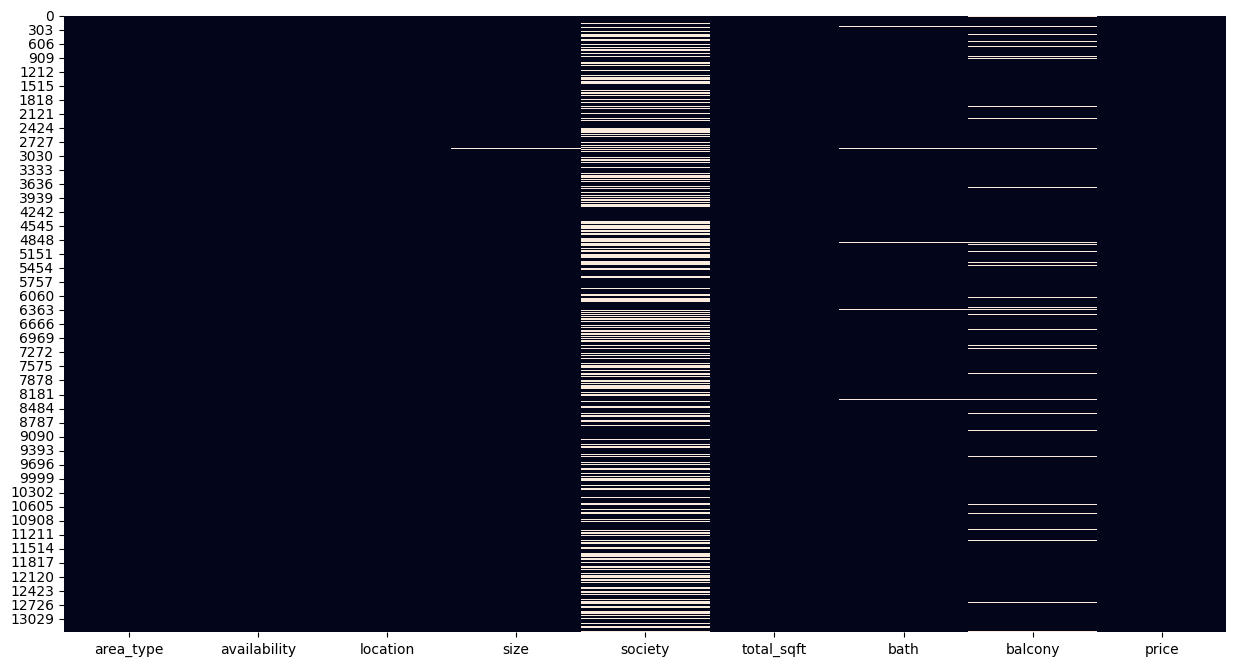

In [36]:
# missing values heatmap
plt.figure(figsize=(15,8))
sns.heatmap(df.isnull() , cbar=False)
plt.show()

In [37]:
# duplicates values
df.duplicated().sum()

np.int64(529)

In [38]:
df = df.drop_duplicates()
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13314,Super built-up Area,Ready To Move,Green Glen Layout,3 BHK,SoosePr,1715,3.0,3.0,112.00
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00


In [39]:
# unique values
for col in df.columns:
    print(col, ":", df[col].nunique())

area_type : 4
availability : 81
location : 1305
size : 31
society : 2688
total_sqft : 2117
bath : 19
balcony : 4
price : 1994


In [40]:
# cateogrical columns
df.select_dtypes(include='object').columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft'],
      dtype='object')

In [41]:
# numerical columns
df.select_dtypes(include=np.number).columns

Index(['bath', 'balcony', 'price'], dtype='object')

In [42]:
# missing value percentage
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': missing_percent
})

missing_df.sort_values(by='Percentage', ascending=False)

,Missing Values,Percentage
society,5328,41.654288
balcony,605,4.729888
bath,73,0.570714
size,16,0.125088
location,1,0.007818
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


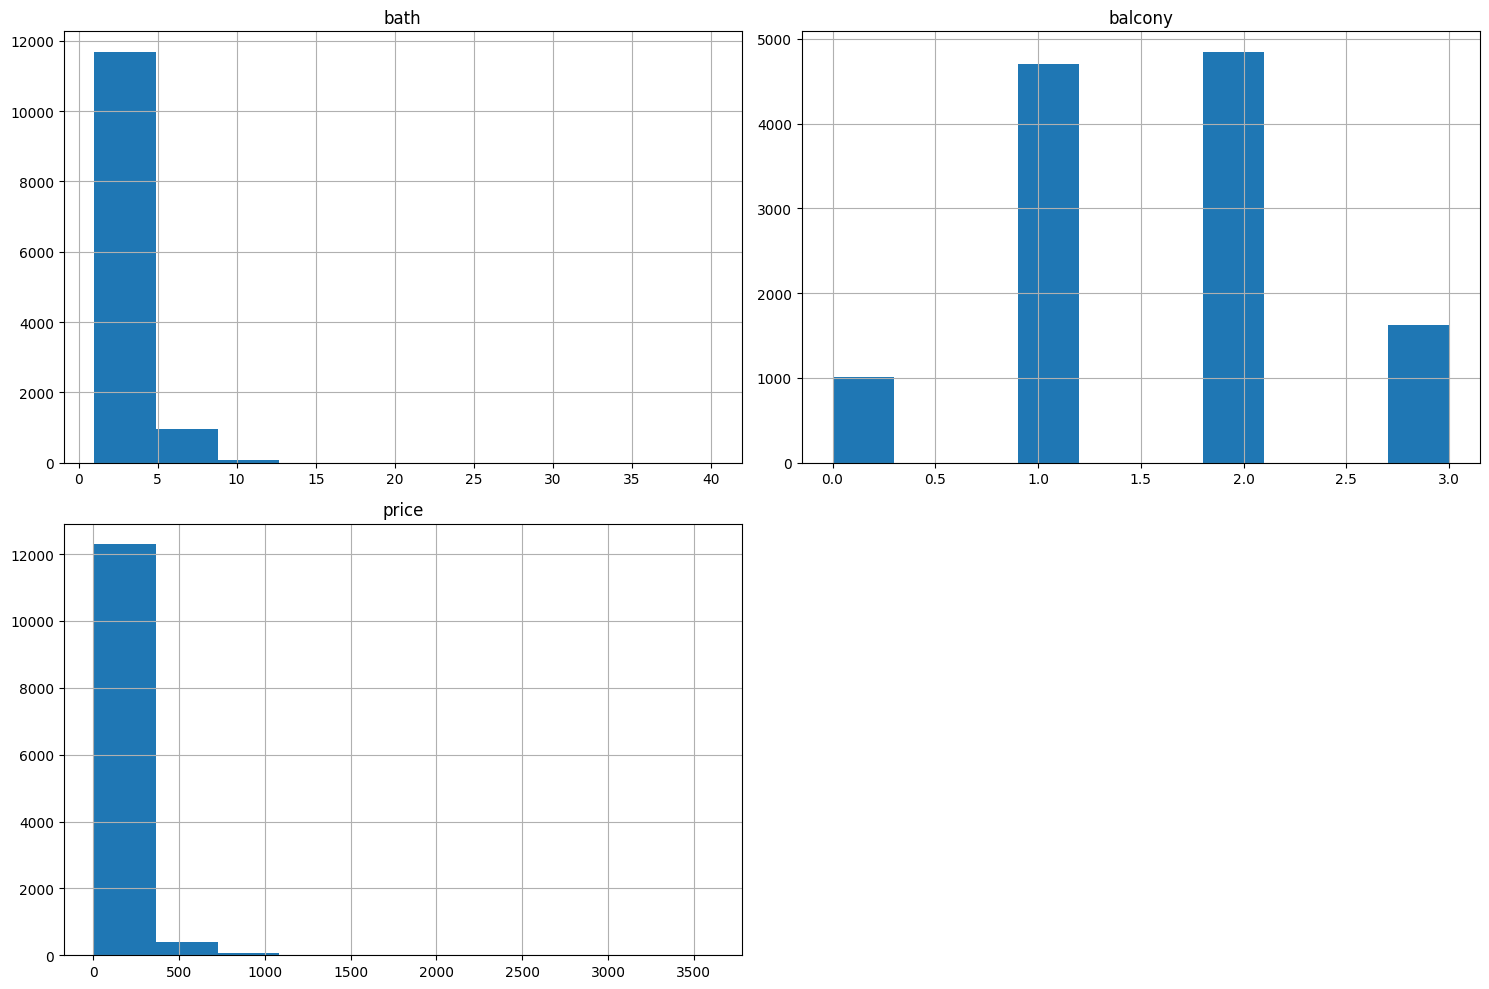

In [43]:
# numerical column distribution
df.hist(figsize=(15, 10))

plt.tight_layout()
plt.show()

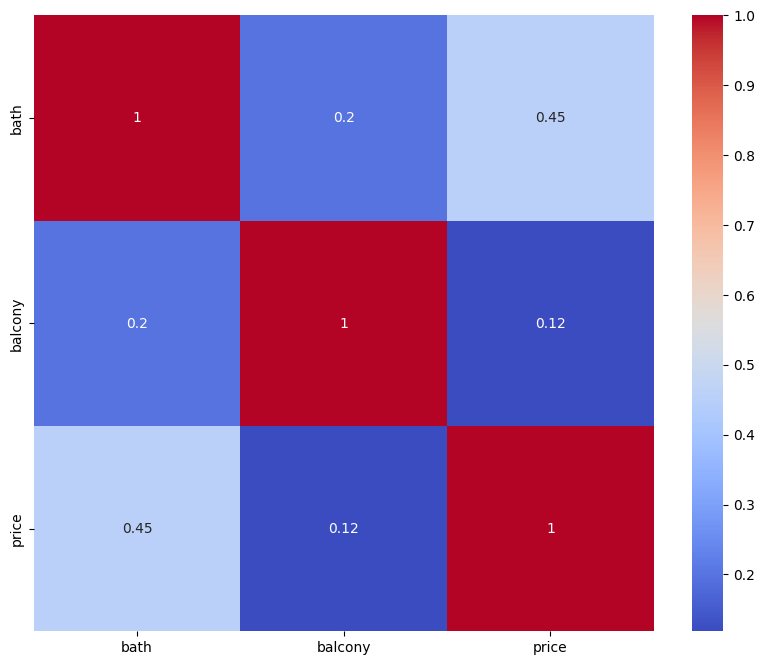

In [44]:
# Corelatrion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [45]:
# Categorical Data Check
for col in df.select_dtypes(include='object').columns:
    print("\n", col)
    print(df[col].value_counts().head(10))


 area_type
area_type
Super built-up  Area    8317
Built-up  Area          2398
Plot  Area              1989
Carpet  Area              87
Name: count, dtype: int64

 availability
availability
Ready To Move    10172
18-May             292
18-Dec             284
18-Apr             269
18-Aug             187
19-Dec             176
18-Jul             131
18-Mar             130
18-Jun              98
20-Dec              94
Name: count, dtype: int64

 location
location
Whitefield               523
Sarjapur  Road           379
Electronic City          287
Kanakpura Road           249
Thanisandra              229
Yelahanka                210
Marathahalli             169
Hebbal                   161
Raja Rajeshwari Nagar    159
Uttarahalli              157
Name: count, dtype: int64

 size
size
2 BHK        4931
3 BHK        4120
4 Bedroom     824
4 BHK         574
3 Bedroom     535
1 BHK         521
2 Bedroom     314
5 Bedroom     291
6 Bedroom     191
1 Bedroom     104
Name: count, dtype: int6

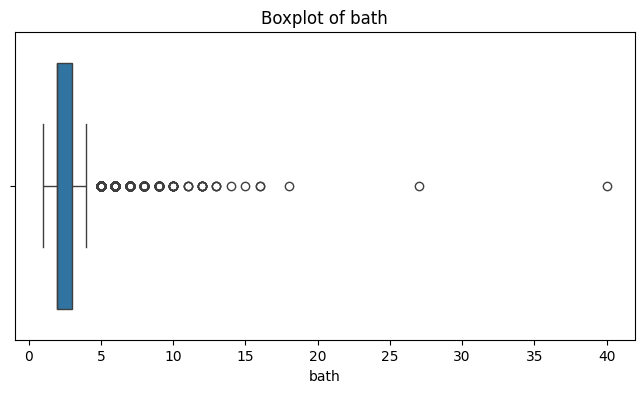

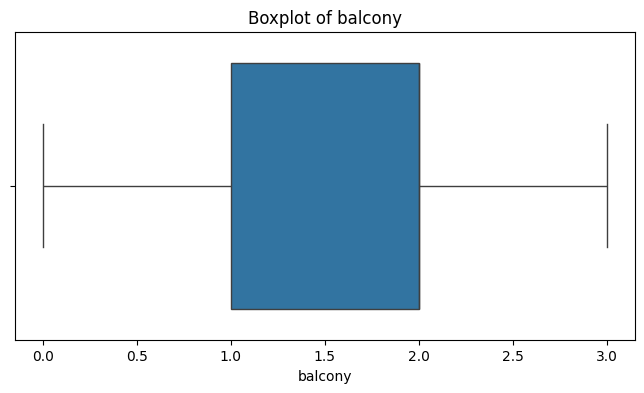

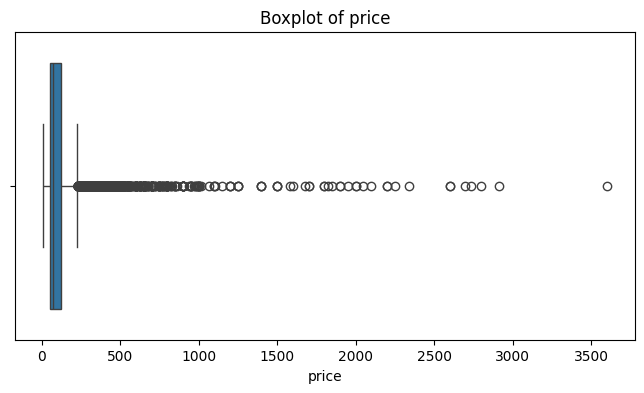

In [46]:
# outliers check
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [47]:
# dataset cleaning
df['total_sqft'].head(20)

,total_sqft
0,1056
1,2600
2,1440
3,1521
4,1200
5,1170
6,2732
7,3300
8,1310
9,1020


In [48]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [49]:
# Now ab data preprocessing ho gya hn now model predictv krega

# X and y banyenge
X = df.drop('price', axis=1)
y = df['price']
print(X.shape)
print(y.shape)

(12791, 8)
(12791,)


In [50]:
# train,test,spilit
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(10232, 8)
(2559, 8)
(10232,)
(2559,)


In [51]:
print(df.dtypes)

area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object


In [52]:
df = df.drop(['availability', 'society'], axis=1)

print(df.head())

              area_type                  location       size total_sqft  bath  \
0  Super built-up  Area  Electronic City Phase II      2 BHK       1056   2.0   
1            Plot  Area          Chikka Tirupathi  4 Bedroom       2600   5.0   
2        Built-up  Area               Uttarahalli      3 BHK       1440   2.0   
3  Super built-up  Area        Lingadheeranahalli      3 BHK       1521   3.0   
4  Super built-up  Area                  Kothanur      2 BHK       1200   2.0   

   balcony   price  
0      1.0   39.07  
1      3.0  120.00  
2      3.0   62.00  
3      1.0   95.00  
4      1.0   51.00  


In [53]:
df['bhk'] = df['size'].str.extract('(\d+)').astype(float)

print(df[['size', 'bhk']].head(10))

        size  bhk
0      2 BHK  2.0
1  4 Bedroom  4.0
2      3 BHK  3.0
3      3 BHK  3.0
4      2 BHK  2.0
5      2 BHK  2.0
6      4 BHK  4.0
7      4 BHK  4.0
8      3 BHK  3.0
9  6 Bedroom  6.0


<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1630/1168909754.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['bhk'] = df['size'].str.extract('(\d+)').astype(float)


In [54]:
X = df.drop('price', axis=1)

In [55]:
y = df['price']

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(10232, 7)
(2559, 7)
(10232,)
(2559,)


In [57]:
print(X_train.dtypes)

area_type      object
location       object
size           object
total_sqft     object
bath          float64
balcony       float64
bhk           float64
dtype: object


In [58]:
print(df.dtypes)

area_type      object
location       object
size           object
total_sqft     object
bath          float64
balcony       float64
price         float64
bhk           float64
dtype: object


In [59]:
df = pd.get_dummies(
    df,
    columns=['area_type', 'location'],
    drop_first=True
)

In [60]:
print(df.dtypes)

size                              object
total_sqft                        object
bath                             float64
balcony                          float64
price                            float64
                                  ...   
location_t.c palya                  bool
location_tc.palya                   bool
location_vinayakanagar              bool
location_white field,kadugodi       bool
location_whitefiled                 bool
Length: 1313, dtype: object


In [61]:
X = df.drop('price', axis=1)
y = df['price']

print(X.dtypes)

size                              object
total_sqft                        object
bath                             float64
balcony                          float64
bhk                              float64
                                  ...   
location_t.c palya                  bool
location_tc.palya                   bool
location_vinayakanagar              bool
location_white field,kadugodi       bool
location_whitefiled                 bool
Length: 1312, dtype: object


In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [63]:
def convert_sqft(x):
    try:
        values = str(x).split('-')

        if len(values) == 2:
            return (float(values[0]) + float(values[1])) / 2

        return float(x)

    except:
        return np.nan

In [64]:
df['total_sqft'] = df['total_sqft'].apply(convert_sqft)

In [65]:
print(df['total_sqft'].head(20))
print(df['total_sqft'].dtype)

0     1056.0
1     2600.0
2     1440.0
3     1521.0
4     1200.0
5     1170.0
6     2732.0
7     3300.0
8     1310.0
9     1020.0
10    1800.0
11    2785.0
12    1000.0
13    1100.0
14    2250.0
15    1175.0
16    1180.0
17    1540.0
18    2770.0
19    1100.0
Name: total_sqft, dtype: float64
float64


In [66]:
print(df['total_sqft'].isnull().sum())

46


In [67]:
df['total_sqft'] = df['total_sqft'].fillna(
    df['total_sqft'].median()
)

In [68]:
X = df.drop('price', axis=1)
y = df['price']

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [71]:
print(X_train.select_dtypes(include='object').columns)

Index(['size'], dtype='object')


In [72]:
print(X_train.isnull().sum())

size                              13
total_sqft                         0
bath                              60
balcony                          477
bhk                               13
                                ... 
location_t.c palya                 0
location_tc.palya                  0
location_vinayakanagar             0
location_white field,kadugodi      0
location_whitefiled                0
Length: 1312, dtype: int64


In [73]:
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

size        13
bath        60
balcony    477
bhk         13
dtype: int64


In [74]:
X = X.fillna(X.median(numeric_only=True))

In [75]:
print(X.select_dtypes(include='object').columns)

Index(['size'], dtype='object')


In [76]:
print(X.select_dtypes(include='object').columns)

Index(['size'], dtype='object')


In [79]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Drop the non-numeric 'size' column from features
if 'size' in X.columns:
    X = X.drop('size', axis=1)

# Re-split the updated features and target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [80]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!
